# 12주차 · 데이터에서 패턴과 관계 찾기

## 자주 사용하는 함수와 메서드

`data`는 주문 한 건이 한 행인 표이고, `slot`은 날짜·매장·시간대별로 집계한 표입니다. 아래 예시는 각 도구의 사용 형태를 보여 줍니다.

| 구분 | 함수·메서드 | 하는 일 | 사용 예시 |
|---|---|---|---|
| 묶어서 계산 | `groupby()` | 같은 기준의 행을 묶습니다. 뒤에 계산 방법을 붙입니다. | `slot.groupby("staff")["wait"].mean()` |
| 개수 | `count()` | 비어 있지 않은 값의 개수를 셉니다. | `data.groupby("order_hour")["order_id"].count()` |
| 평균·중앙값 | `mean()`, `median()` | 값의 평균 또는 크기순 가운데 값을 구합니다. | `waits.mean()`, `waits.median()` |
| 합계·조건 건수 | `sum()` | 값을 더합니다. 불리언 값에서는 `True`의 개수를 셉니다. | `valid.groupby("event_day")["long_wait"].sum()` |
| 관계 | `corr()` | 두 수치 사이의 피어슨 상관계수를 구합니다. | `slot["orders"].corr(slot["wait"])` |
| 최댓값과 위치 | `max()`, `idxmax()` | `max()`는 가장 큰 값, `idxmax()`는 그 값의 인덱스 이름을 돌려줍니다. | `march_orders.max()`, `march_orders.idxmax()` |
| 값별 비율 | `value_counts(normalize=True)` | 값마다 차지하는 비율을 구합니다. 100을 곱하면 백분율입니다. | `staff4["order_hour"].value_counts(normalize=True) * 100` |
| 표 만들기 | `pd.DataFrame()` | 여러 계산 결과를 열로 묶어 표를 만듭니다. | `pd.DataFrame({"3월": march_orders, "8월": august_orders})` |
| 인덱스 정리 | `reset_index()` | 집계 결과의 인덱스를 일반 열로 옮깁니다. | `slot.reset_index()` |
| 대표값 | `first()` | 각 묶음에서 열의 첫 번째 유효값을 가져옵니다. | `data.groupby(keys)["event_day"].first()` |
| 정렬 | `sort_values()` | 지정한 열의 값을 기준으로 행을 정렬합니다. | `unusual.sort_values("wait", ascending=False)` |
| 미리보기·반올림 | `head()`, `round()` | 앞부분을 보거나 소수 자릿수를 정리합니다. | `slot.head()`, `staff_all.round(2)` |
| 복사·결측 제외 | `copy()`, `dropna()` | 복사본을 만들거나 비어 있는 값이 있는 행을 제외합니다. | `data.copy()`, `data.dropna(subset=["wait_minutes"])` |
| 결측 채우기 | `fillna()` | 비어 있는 값을 지정한 값으로 채웁니다. 채우는 값의 의미를 확인합니다. | `staff_hours.fillna(0)` |
| 특정 기록 제외 | `drop()` | 지정한 인덱스의 행을 제외한 결과를 만듭니다. | `waits.drop(index=largest_order)` |
| 그래프 | `plot()` | `kind`로 선·막대·산점도를 선택합니다. | `monthly.plot(kind="line")`, `slot.plot(kind="scatter", x="orders", y="wait")` |
| 제목·축 이름 | `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | 그래프가 무엇을 비교하는지와 단위를 표시합니다. | `plt.ylabel("평균 대기시간(분)")` |
| 축 범위·출력 | `plt.xlim()`, `plt.ylim()`, `plt.tight_layout()`, `plt.show()` | 비교할 축 범위를 맞추고 배치를 정리해 그래프를 출력합니다. | `plt.xlim(0, 130)`, `plt.show()` |

**함수와 함께 자주 쓰는 선택 방법:** `표[조건]`은 조건에 맞는 행을 고릅니다. `loc[이름]`은 인덱스 이름으로, `iloc[위치]`는 0부터 세는 위치로 값을 고릅니다. `loc`와 `iloc`는 함수 호출이 아니므로 소괄호 대신 대괄호를 사용합니다.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

fonts = {font.name for font in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 20)

주문 기록의 처음 몇 행을 확인합니다. 한 행은 주문 한 건이며, 날짜·시간대·매장·대기시간 등이 같은 주문에 연결되어 있습니다.

In [2]:
csv_path = Path("week11_cafe_orders.csv")
if not csv_path.exists():
    csv_path = Path("../강의교재/data/week11_cafe_orders.csv")
if not csv_path.exists():
    csv_path = Path("강의교재/data/week11_cafe_orders.csv")

In [3]:
raw = pd.read_csv(csv_path, encoding="utf-8-sig")
raw.head(4)

,order_id,order_date,order_time,weekday,order_hour,store_location,menu_name,order_count,unit_price,sales_amount,wait_minutes,payment_method,weather,event_day,staff_count
0,2526,2026-03-02,09:01:32,월,9,공학관점,아메리카노,1,2500,2500,3.3,NaN,비,행사,3
1,2015,2026-03-02,09:01:51,월,9,학생회관점,카페라테,1,3500,3500,9.0,NaN,비,행사,2
2,2289,2026-03-02,09:01:56,월,9,도서관점,바닐라라테,2,4000,8000,5.2,카드,NaN,행사,3
3,2527,2026-03-02,09:04:47,월,9,공학관점,바닐라라테,1,4000,4000,4.0,NaN,비,행사,3


계산에는 같은 주문이 중복되지 않고, 수량이 기록 범위 안에 있는 행을 사용합니다. 음수 대기시간은 비어 있는 값으로 바꾸고 긴 대기시간 기록은 그대로 둡니다. 이 코드는 분석할 표 `data`를 준비하며 원본 `raw`는 보존합니다.

In [4]:
data = raw.drop_duplicates().copy()
data = data[(data["order_count"] >= 1) & (data["order_count"] <= 6)]
data = data.copy()
data.loc[data["wait_minutes"] < 0, "wait_minutes"] = np.nan
data["order_date"] = pd.to_datetime(data["order_date"])
print("주문 기록:", len(data), "건")

주문 기록: 103449 건


## 날짜별 차이에서 반복되는 요일 찾기

주문이 많은 날과 적은 날을 먼저 살펴봅니다. 원자료에서 날짜 하나에 여러 주문이 있으므로 날짜별로 행의 개수를 세어 하루 주문 건수를 만듭니다. `order_count`를 더하면 음료 수량이 되므로 여기서는 비어 있지 않은 주문 번호를 세는 `count()`를 사용합니다.

In [5]:
daily_count = data.groupby(["order_date", "weekday"])["order_id"].count()
daily_count.head()

order_date  weekday
2026-03-02  월          778
2026-03-03  화          824
2026-03-04  수          752
2026-03-05  목          774
2026-03-06  금          873
Name: order_id, dtype: int64

집계 결과의 날짜와 요일은 왼쪽 인덱스에 있습니다. `reset_index()`로 이를 일반 열로 옮기고, 주문 건수 열의 이름을 `orders`로 정합니다.

In [6]:
daily = daily_count.reset_index()
daily.columns = ["order_date", "weekday", "orders"]
daily.head()

,order_date,weekday,orders
0,2026-03-02,월,778
1,2026-03-03,화,824
2,2026-03-04,수,752
3,2026-03-05,목,774
4,2026-03-06,금,873


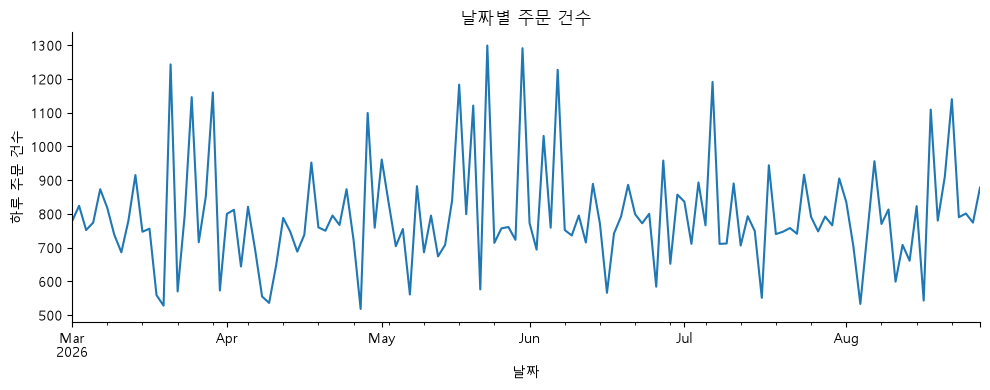

In [7]:
daily.plot(kind="line", x="order_date", y="orders", legend=False)
plt.title("날짜별 주문 건수")
plt.xlabel("날짜")
plt.ylabel("하루 주문 건수")
plt.tight_layout()
plt.show()

날짜별 선은 위아래로 움직이며, 높은 날과 낮은 날이 반복해서 나타납니다. 이 모양만으로 반복 간격이나 원인을 알 수는 없습니다. 다음 질문을 **“요일별로 묶으면 주문 건수에 일정한 차이가 있는가?”**로 좁혀 봅니다.

요일별 주문 합계를 비교하기 전에 날짜 수를 확인합니다. 날짜 수가 다르면 주문 합계에 영업일 수의 차이도 섞이므로 하루 평균을 비교하는 편이 질문에 맞습니다.

In [ ]:
weekday_count = daily.groupby("weekday")["orders"].count()
weekday_mean = daily.groupby("weekday")["orders"].mean()
weekday_median = daily.groupby("weekday")["orders"].median()

In [ ]:
weekday_stats = pd.DataFrame({
    "count": weekday_count,
    "mean": weekday_mean,
    "median": weekday_median
})
weekday_order = ["월", "화", "수", "목", "금"]
weekday_stats = weekday_stats.loc[weekday_order]
weekday_stats.round(2)

,count,mean,median
weekday,,,
월,26,803.65,772.0
화,26,746.38,749.0
수,26,794.12,759.5
목,26,704.46,730.5
금,26,930.19,899.0


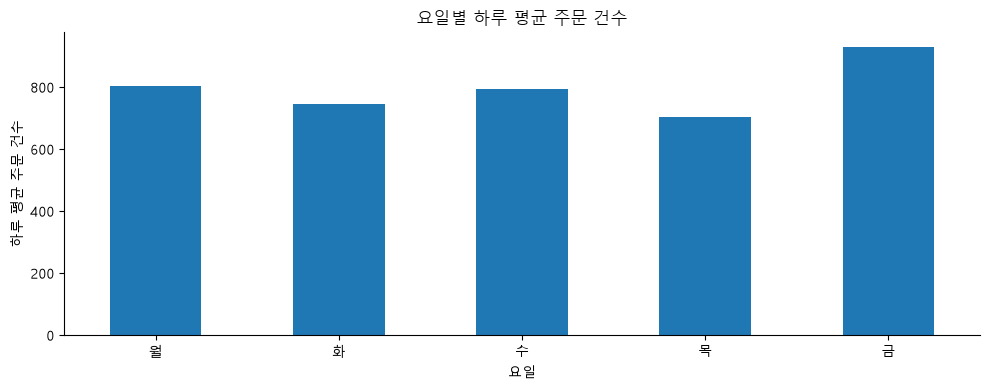

In [ ]:
weekday_stats["mean"].plot(kind="bar", rot=0)
plt.title("요일별 하루 평균 주문 건수")
plt.xlabel("요일")
plt.ylabel("하루 평균 주문 건수")
plt.tight_layout()
plt.show()

각 요일은 26일씩 기록되어 있습니다. 금요일 평균은 약 930건, 목요일 평균은 약 704건으로 차이가 납니다. 이 표의 `count`는 주문 수가 아닌 **날짜 수**입니다. 평균뿐 아니라 중앙값도 함께 보면 몇몇 높은 날짜에 결과가 크게 좌우되는지 생각할 수 있습니다.

금요일의 평균이 높다는 관찰에서 **“이 차이가 특정 기간에만 나타난 것은 아닐까?”**라는 질문이 생깁니다. 전반과 후반으로 나누어 같은 계산을 적용합니다.

날짜가 6월 1일보다 이른 행과 그 이후의 행을 각각 고릅니다. 새로운 기간 열을 만들지 않고 두 표에서 같은 계산을 실행합니다.

In [ ]:
daily_early = daily[daily["order_date"] < "2026-06-01"]
daily_late = daily[daily["order_date"] >= "2026-06-01"]
early_weekday = daily_early.groupby("weekday")["orders"].mean()
late_weekday = daily_late.groupby("weekday")["orders"].mean()

In [ ]:
weekday_period = pd.DataFrame({"3~5월": early_weekday, "6~8월": late_weekday})
weekday_period = weekday_period.loc[weekday_order]
weekday_period.round(1)

,3~5월,6~8월
weekday,,
월,813.6,793.7
화,727.0,765.8
수,799.3,788.9
목,690.5,718.4
금,944.0,916.4


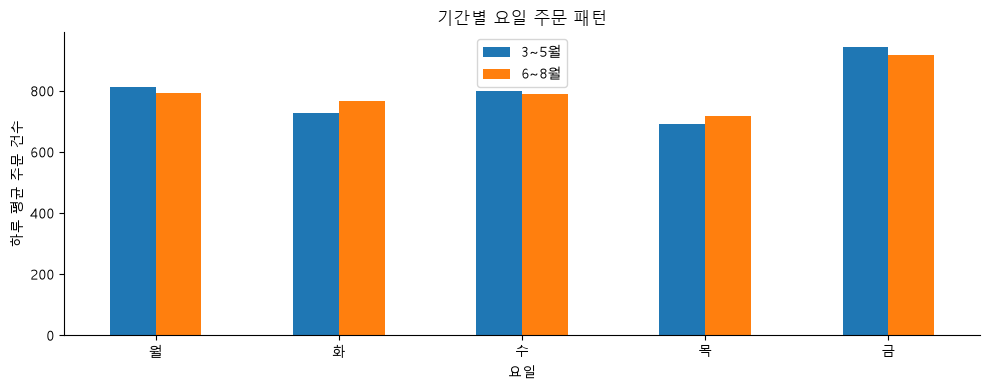

In [ ]:
weekday_period.plot(kind="bar", rot=0)
plt.title("기간별 요일 주문 패턴")
plt.xlabel("요일")
plt.ylabel("하루 평균 주문 건수")
plt.tight_layout()
plt.show()

금요일 평균은 3~5월 약 944건, 6~8월 약 916건이며 두 기간 모두 다른 요일보다 높습니다. 따라서 금요일의 높은 주문량은 한 기간의 몇 날짜에만 나타난 현상이라는 설명보다, 두 기간에서 반복해서 관찰한 경향이라는 설명에 근거가 있습니다. 요일이 주문 증가의 원인인지는 이 비교만으로 알 수 없습니다.

**확인하기:** 두 기간에서 금요일이 모두 높더라도, 이를 주말이나 다른 카페에도 그대로 적용할 수 있을까요? 관찰한 대상과 기간을 포함해 결론 한 문장을 써 봅니다.

## 하루 안에서 반복되는 혼잡 시간 찾기

요일별로 높은 날을 찾았지만 하루 중 언제 주문이 몰리는지는 아직 알 수 없습니다. 이번에는 한 날짜의 한 매장을 한 시간씩 나누어 봅니다. 이후의 표 `slot`에서는 **날짜·매장·시간대 하나가 한 행**입니다.

이렇게 집계하면 같은 시간 동안 들어온 주문 건수와 그 주문들의 평균 대기시간을 나란히 비교할 수 있습니다. 같은 묶음에 연결된 직원 수와 행사 여부도 함께 살펴봅니다.

In [ ]:
keys = ["order_date", "store_location", "order_hour"]
slot_orders = data.groupby(keys)["order_id"].count()
slot_wait = data.groupby(keys)["wait_minutes"].mean()
slot_orders.head()

order_date  store_location  order_hour
2026-03-02  공학관점            9             16
                            10            13
                            11            20
                            12            52
                            13            51
Name: order_id, dtype: int64

같은 기준으로 구한 주문 건수와 평균 대기시간을 한 표에 놓습니다. 직원 수와 행사 여부도 같은 묶음에서 가져옵니다. 이 기록에서는 한 매장의 같은 날짜·시간대 안에서 직원 수와 행사 여부가 같습니다. 직원 수는 평균을, 행사 여부는 첫 값을 가져옵니다.

In [ ]:
slot_staff = data.groupby(keys)["staff_count"].mean()
slot_event = data.groupby(keys)["event_day"].first()
slot = pd.DataFrame({
    "orders": slot_orders, "wait": slot_wait,
    "staff": slot_staff, "event": slot_event
})
slot.head()

orders      wait  staff event
order_date store_location order_hour                               
2026-03-02 공학관점           9               16  4.520000    3.0    행사
                          10              13  4.969231    3.0    행사
                          11              20  5.478947    3.0    행사
                          12              52  9.609615    4.0    행사
                          13              51  7.715686    4.0    행사

조건으로 날짜와 시각을 고를 수 있도록 인덱스를 열로 바꿉니다. 이 뒤의 분석에서는 이 표 `slot`을 사용합니다.

In [ ]:
slot = slot.reset_index()
slot.head()

,order_date,store_location,order_hour,orders,wait,staff,event
0,2026-03-02,공학관점,9,16,4.520000,3.0,행사
1,2026-03-02,공학관점,10,13,4.969231,3.0,행사
2,2026-03-02,공학관점,11,20,5.478947,3.0,행사
3,2026-03-02,공학관점,12,52,9.609615,4.0,행사
4,2026-03-02,공학관점,13,51,7.715686,4.0,행사


같은 시각의 여러 날짜·매장을 묶어 평균을 구합니다. `orders`의 평균은 한 매장에서 한 시간 동안 받은 주문의 평균이고, `wait`의 평균은 각 날짜·매장·시간대 평균에 같은 비중을 준 값입니다.

In [ ]:
hour_orders = slot.groupby("order_hour")["orders"].mean()
hour_wait = slot.groupby("order_hour")["wait"].mean()
hourly = pd.DataFrame({"orders": hour_orders, "wait": hour_wait})
hourly.round(2)

,orders,wait
order_hour,,
9,14.31,3.94
10,17.52,4.44
11,25.52,4.95
12,56.53,8.48
13,44.71,7.12
14,20.65,4.56
15,22.49,4.72
16,25.41,5.14
17,22.11,4.92


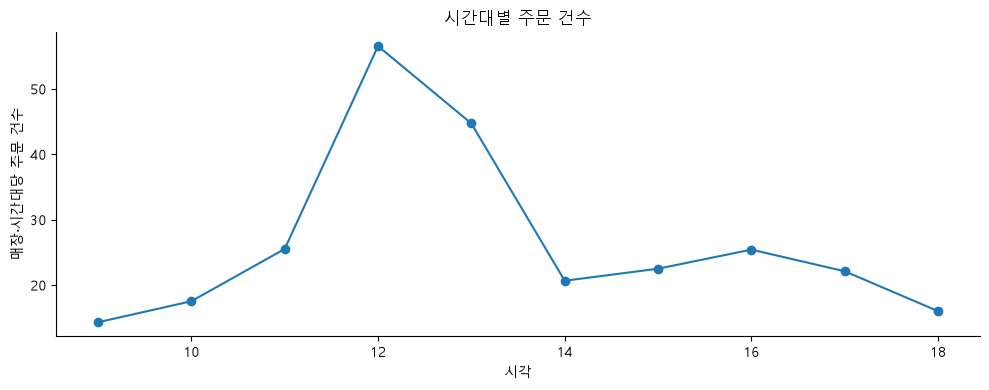

In [ ]:
hour_orders.plot(kind="line", marker="o")
plt.title("시간대별 주문 건수")
plt.xlabel("시각")
plt.ylabel("매장·시간대당 주문 건수")
plt.tight_layout()
plt.show()

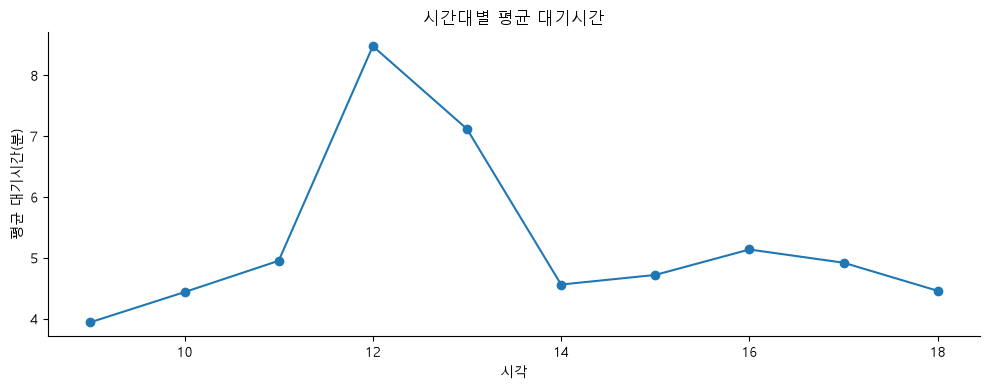

In [ ]:
hour_wait.plot(kind="line", marker="o")
plt.title("시간대별 평균 대기시간")
plt.xlabel("시각")
plt.ylabel("평균 대기시간(분)")
plt.tight_layout()
plt.show()

주문 건수와 평균 대기시간 모두 12시에 가장 높고 13시에도 높은 편입니다. 12시에는 매장·시간대당 평균 약 56.5건의 주문, 평균 약 8.48분의 대기가 나타납니다.

여기서 발견한 것은 **두 값의 시간대별 모양이 비슷하다**는 점입니다. 월별 자료에서도 같은 시각에 주문이 몰리는지 확인하면 시간적 반복을 더 구체적으로 설명할 수 있습니다.

월별 자료도 한 달씩 골라 같은 계산을 반복할 수 있습니다. 먼저 3월과 8월을 비교합니다. 날짜 조건과 `groupby()`는 앞에서 사용한 형태와 같습니다.

In [ ]:
march = slot[slot["order_date"] < "2026-04-01"]
august = slot[slot["order_date"] >= "2026-08-01"]
march_orders = march.groupby("order_hour")["orders"].mean()
august_orders = august.groupby("order_hour")["orders"].mean()
monthly = pd.DataFrame({"3월": march_orders, "8월": august_orders})
monthly.round(2)

,3월,8월
order_hour,,
9,14.29,14.17
10,17.61,17.80
11,26.68,26.57
12,56.55,56.53
13,45.61,42.38
14,20.47,20.65
15,23.06,21.72
16,24.80,26.55
17,21.47,22.73


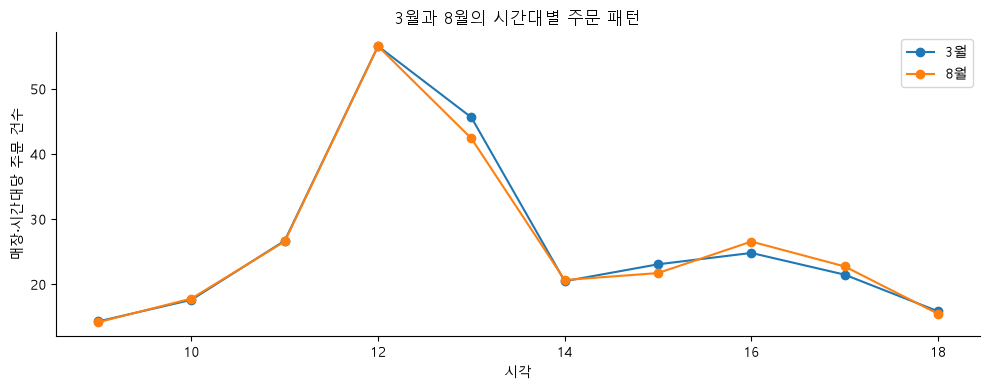

In [ ]:
monthly.plot(kind="line", marker="o")
plt.title("3월과 8월의 시간대별 주문 패턴")
plt.xlabel("시각")
plt.ylabel("매장·시간대당 주문 건수")
plt.tight_layout()
plt.show()

In [ ]:
print("3월에 주문이 가장 많은 시각:", march_orders.idxmax())
print("8월에 주문이 가장 많은 시각:", august_orders.idxmax())

3월에 주문이 가장 많은 시각: 12
8월에 주문이 가장 많은 시각: 12


3월과 8월의 선에서 12시의 최고점과 13시의 높은 값이 반복됩니다. 선의 높이는 달마다 달라도 하루 안에서 주문이 몰리는 시각에는 공통점이 있습니다. 고정된 시간 간격으로 나타나는 반복과 장기간의 증가·감소를 구분해서 설명하는 접근입니다. [시간 패턴과 반복 구간의 비교](https://otexts.com/fpp3/graphics.html)

**지금까지의 결론:** 날짜별 차이를 요일별로 나누어 금요일의 높은 주문량을 찾았고, 하루 안에서는 여러 달에 걸쳐 점심 주문 집중을 확인했습니다. 이 자료는 평일 기록이므로 토·일요일 값이 없는 상태를 주문 0건으로 해석하면 안 됩니다.

## 함께 높아지는 두 값의 관계 살펴보기

시간대별 주문량과 대기시간이 함께 높아졌습니다. 이제 시간대 평균 열 개를 비교하는 데서 나아가, 날짜·매장·시간대 각각을 점으로 표시합니다. 질문은 **“주문 건수가 많은 매장·시간대일수록 평균 대기시간도 긴가?”**입니다.

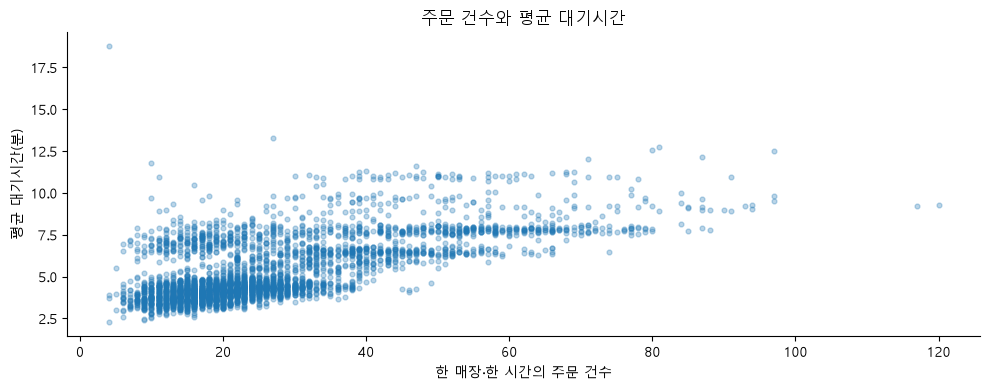

In [ ]:
slot.plot(kind="scatter", x="orders", y="wait", s=12, alpha=0.3)
plt.title("주문 건수와 평균 대기시간")
plt.xlabel("한 매장·한 시간의 주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.tight_layout()
plt.show()

In [ ]:
correlation = slot["orders"].corr(slot["wait"])
print("상관계수:", round(correlation, 3))

상관계수: 0.67


산점도는 전체적으로 오른쪽 위로 향하고, 상관계수는 약 0.67입니다. 이 자료에서 주문 건수와 평균 대기시간 사이에 양의 선형 관계가 관찰됩니다. 피어슨 상관계수는 선형 관계를 요약하므로 0에 가깝다고 해서 모든 형태의 관계가 없다고 판단하지는 않습니다.

점들은 한 줄에 모이지 않고 여러 높이의 띠를 이룹니다. 주문 건수가 비슷해도 대기시간이 다른 사례가 있습니다. 다음 질문은 **“이 띠들이 어떤 조건의 차이와 연결되어 있을까?”**입니다. 산점도를 읽을 때 방향과 함께 형태·퍼짐·예외를 확인합니다. [NIST의 산점도 해설](https://itl.nist.gov/div898/handbook/eda/section3/eda33q.htm)

직원 수별로 행을 고른 뒤 산점도를 하나씩 그립니다. 그래프마다 가로·세로축의 범위를 같게 해야 위치와 퍼짐을 비교할 수 있습니다.

In [ ]:
staff2 = slot[slot["staff"] == 2]
staff3 = slot[slot["staff"] == 3]
staff4 = slot[slot["staff"] == 4]

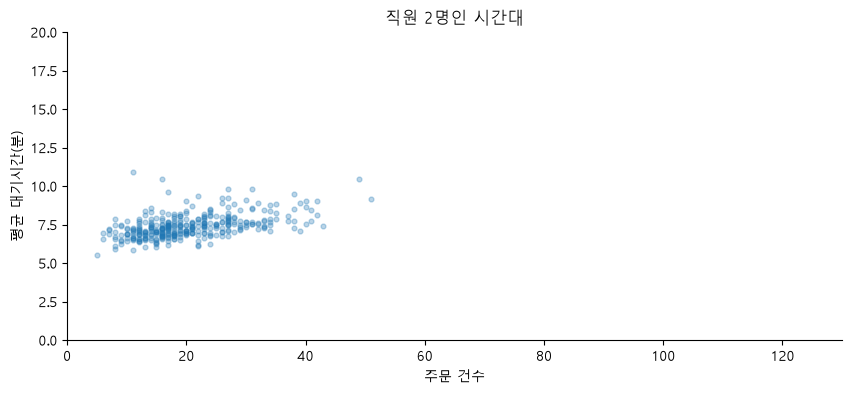

In [ ]:
staff2.plot(kind="scatter", x="orders", y="wait", s=12, alpha=0.3)
plt.title("직원 2명인 시간대")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.xlim(0, 130)
plt.ylim(0, 20)
plt.show()

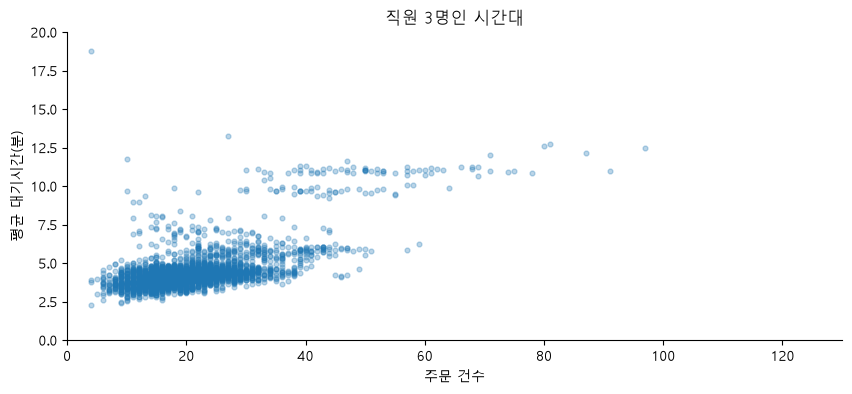

In [ ]:
staff3.plot(kind="scatter", x="orders", y="wait", s=12, alpha=0.3)
plt.title("직원 3명인 시간대")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.xlim(0, 130)
plt.ylim(0, 20)
plt.show()

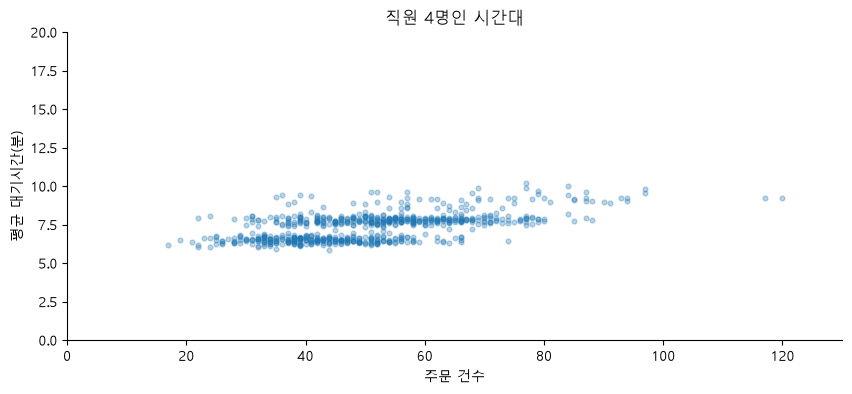

In [ ]:
staff4.plot(kind="scatter", x="orders", y="wait", s=12, alpha=0.3)
plt.title("직원 4명인 시간대")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.xlim(0, 130)
plt.ylim(0, 20)
plt.show()

직원 수별로 나누면 점이 놓인 주문 규모와 높이가 달라집니다. 직원 4명인 집단은 주문 건수가 많은 쪽에 집중되어 있습니다. 따라서 직원 수만으로 묶은 평균을 해석할 때는 각 집단에 어떤 시간대가 들어 있는지도 확인해야 합니다.

## 직원 수를 나누었을 때 생기는 새로운 의문

산점도에서 본 집단 차이를 숫자로 확인합니다. 직원 수마다 관측한 시간대 수, 평균 주문 건수, 평균 대기시간을 함께 구합니다. 집단의 크기와 주문 규모를 함께 읽어야 평균 대기시간을 비교할 때 생기는 의문을 구체화할 수 있습니다.

In [ ]:
staff_all_count = slot.groupby("staff")["orders"].count()
staff_all_orders = slot.groupby("staff")["orders"].mean()
staff_all_wait = slot.groupby("staff")["wait"].mean()

In [ ]:
staff_all = pd.DataFrame({
    "slots": staff_all_count,
    "orders": staff_all_orders,
    "wait": staff_all_wait
})
staff_all.round(2)

,slots,orders,wait
staff,,,
2.0,336,20.45,7.42
3.0,2887,21.54,4.53
4.0,677,50.78,7.37


전체에서는 직원 3명인 시간대의 평균 대기가 약 4.53분, 4명인 시간대는 약 7.37분입니다. 동시에 평균 주문 건수는 각각 약 21.5건과 50.8건으로 차이가 큽니다. 이 결과를 보고 직원이 많으면 대기가 길어진다고 해석하기 전에, 두 집단이 주로 어느 시각의 기록으로 이루어져 있는지 확인합니다.

직원 수별로 고른 표에서 각 시각의 비율을 구하면 집단의 구성을 비교할 수 있습니다.

직원 수별로 추출한 표에서 시간대별 비율을 구합니다. `value_counts(normalize=True)`는 해당 표 안에서 각 값이 차지하는 비율을 돌려줍니다. 100을 곱하면 백분율이 됩니다.

In [ ]:
hours2 = staff2["order_hour"].value_counts(normalize=True) * 100
hours3 = staff3["order_hour"].value_counts(normalize=True) * 100
hours4 = staff4["order_hour"].value_counts(normalize=True) * 100
hours4

order_hour
13    50.812408
12    49.187592
Name: proportion, dtype: float64

In [ ]:
staff_hours = pd.DataFrame({"직원 2명": hours2, "직원 3명": hours3, "직원 4명": hours4})
staff_hours = staff_hours.fillna(0)
staff_hours = staff_hours.sort_index()
staff_hours.round(1)

,직원 2명,직원 3명,직원 4명
order_hour,,,
9,12.5,12.1,0.0
10,15.5,11.7,0.0
11,12.8,12.0,0.0
12,0.0,2.0,49.2
13,0.0,1.6,50.8
14,11.0,12.2,0.0
15,11.6,12.2,0.0
16,11.0,12.2,0.0
17,10.1,12.3,0.0


표에서 직원 4명인 기록은 12시와 13시에만 나타납니다. 직원 3명 집단에는 주문이 적고 대기가 짧은 시간대가 많이 들어 있습니다. 전체 평균에는 **직원 수의 차이와 시간대 구성의 차이가 함께 섞여 있습니다.**

표에서 직원 수별 열의 합계는 각각 100%입니다. 해당 시각의 기록이 없는 집단은 비율을 0으로 표시합니다. 그래프에서 같은 색 막대들의 합계가 100%이며, 분모는 각 직원 수 집단의 전체 시간대 수입니다.

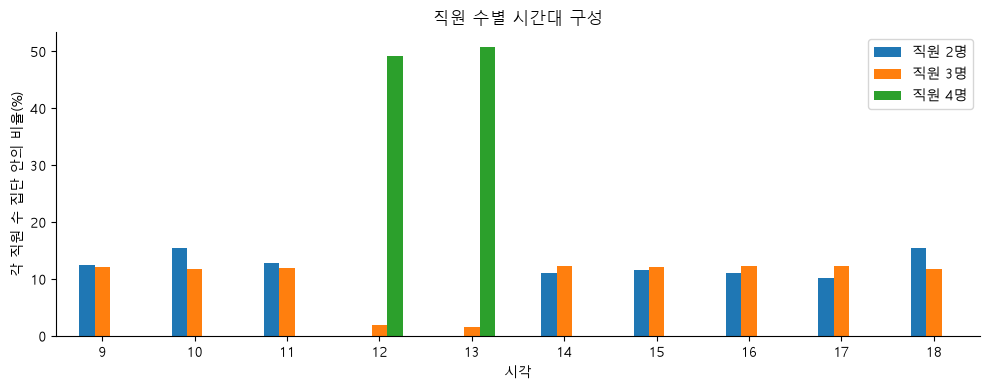

In [ ]:
staff_hours.plot(kind="bar", rot=0)
plt.title("직원 수별 시간대 구성")
plt.xlabel("시각")
plt.ylabel("각 직원 수 집단 안의 비율(%)")
plt.tight_layout()
plt.show()

이제 **“같은 12시 안에서 직원 3명과 4명인 기록은 어떻게 다른가?”**를 확인합니다. 같은 시각으로 비교 범위를 좁혀도 주문 규모가 완전히 같아지는 것은 아니므로 관측 수와 주문 건수를 계속 함께 봅니다.

In [ ]:
at12 = slot[slot["order_hour"] == 12]
at12.head()

,order_date,store_location,order_hour,orders,wait,staff,event
3,2026-03-02,공학관점,12,52,9.609615,4.0,행사
13,2026-03-02,도서관점,12,52,8.971154,4.0,행사
23,2026-03-02,학생회관점,12,59,9.132203,4.0,행사
33,2026-03-03,공학관점,12,54,7.862963,4.0,일반
43,2026-03-03,도서관점,12,44,7.986364,4.0,일반


In [ ]:
staff_12_count = at12.groupby("staff")["orders"].count()
staff_12_orders = at12.groupby("staff")["orders"].mean()
staff_12_wait = at12.groupby("staff")["wait"].mean()

In [ ]:
staff_12 = pd.DataFrame({
    "slots": staff_12_count,
    "orders": staff_12_orders,
    "wait": staff_12_wait
})
staff_12.round(2)

,slots,orders,wait
staff,,,
3.0,57,54.21,11.13
4.0,333,56.93,8.03


In [ ]:
compare_staff = pd.DataFrame({"전체 시간대": staff_all_wait, "12시": staff_12_wait})
compare_staff = compare_staff.loc[[3, 4]]
compare_staff.round(2)

,전체 시간대,12시
staff,,
3.0,4.53,11.13
4.0,7.37,8.03


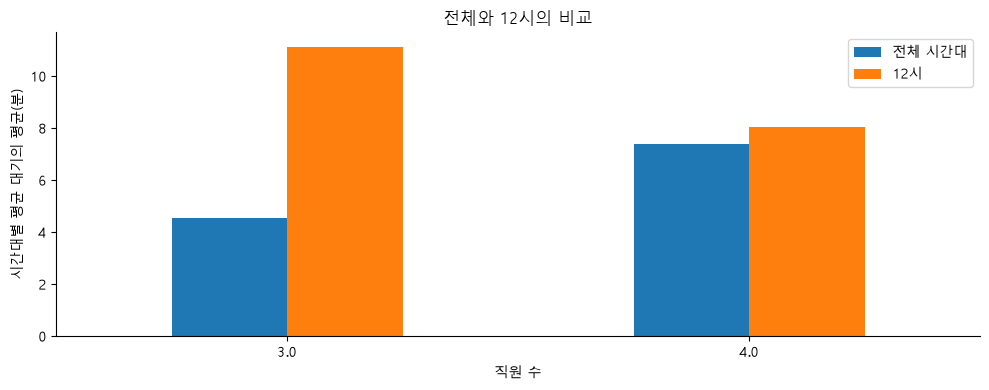

In [ ]:
compare_staff.plot(kind="bar", rot=0)
plt.title("전체와 12시의 비교")
plt.xlabel("직원 수")
plt.ylabel("시간대별 평균 대기의 평균(분)")
plt.tight_layout()
plt.show()

12시에는 직원 3명 집단이 약 11.13분, 4명 집단이 약 8.03분으로 전체 비교와 순서가 달라집니다. 직원 4명 집단은 전체 자료에서 바쁜 점심 기록만 포함하기 때문에 전체 평균이 더 높게 나타났던 것입니다.

처음의 설명은 **“직원 수가 많은 집단의 전체 평균 대기가 높지만, 시간대 구성이 다르며 12시 안에서는 직원 4명인 집단의 평균 대기가 더 낮다”**로 수정할 수 있습니다. 이와 같은 탐색에서는 다른 변수를 함께 살펴보고 하위 집단에서도 관계가 유지되는지 질문합니다. [패턴을 발견한 뒤 던질 질문](https://r4ds.hadley.nz/EDA#patterns-and-models)

직원 수와 함께 매장·행사·주문 구성도 달라질 수 있으므로, 이 비교로 직원 한 명 증원의 효과를 확정하지는 않습니다.

### 다른 시각에서도 같은 질문 적용하기

12시의 비교에만 의존하지 않고 10시의 직원 2명과 3명 집단을 비교합니다. 집단을 바꾸어도 관측 수·주문 규모·대기시간을 같은 방식으로 계산합니다.

In [ ]:
at10 = slot[slot["order_hour"] == 10]

In [ ]:
staff_10_count = at10.groupby("staff")["orders"].count()
staff_10_orders = at10.groupby("staff")["orders"].mean()
staff_10_wait = at10.groupby("staff")["wait"].mean()

In [ ]:
staff_10 = pd.DataFrame({
    "slots": staff_10_count,
    "orders": staff_10_orders,
    "wait": staff_10_wait
})
staff_10.round(2)

,slots,orders,wait
staff,,,
2.0,52,16.96,7.10
3.0,338,17.61,4.03


10시에는 직원 2명 집단이 약 7.10분, 3명 집단이 약 4.03분입니다. 12시와 10시의 결과 모두 같은 시각 안에서 직원이 적은 집단의 대기가 긴 경향을 보입니다. 이 결론은 비교한 기록에서 관찰한 관계이며, 인원 배치의 원인이나 최적 인원을 알려 주는 결과는 아닙니다.

**확인하기:** 전체에서 직원 3명 집단의 대기가 가장 짧았다는 사실과, 같은 시각 안에서 직원이 적은 집단의 대기가 길었다는 사실을 한 문단으로 함께 설명해 봅니다.

## 평균에서 긴 대기의 비율로 질문 바꾸기

지금까지는 시간대의 평균 대기를 비교했습니다. 평균이 낮아도 일부 주문은 오래 기다릴 수 있습니다. 주문 한 건으로 다시 돌아가 **“각 조건에서 긴 대기가 얼마나 자주 나타나는가?”**를 살펴봅니다.

10분을 초과한 기록을 구분하고, 대기시간이 기록된 주문을 분모로 사용합니다. 10분은 비교를 위한 기준이며 기준을 바꾸면 비율도 바뀝니다. 대기시간이 비어 있는 주문을 10분 이하로 처리하면 긴 대기의 비율이 낮아지므로 먼저 계산 대상에서 제외합니다.

In [ ]:
valid = data.dropna(subset=["wait_minutes"]).copy()
valid["long_wait"] = valid["wait_minutes"] > 10
valid[["wait_minutes", "long_wait"]].head()

,wait_minutes,long_wait
0,3.3,False
1,9.0,False
2,5.2,False
3,4.0,False
4,5.5,False


긴 대기 건수를 유효 주문 수로 나누어 비율을 구합니다. 각 계산을 따로 확인한 뒤 표에 모읍니다.

In [ ]:
hour_count = valid.groupby("order_hour")["long_wait"].count()
hour_long = valid.groupby("order_hour")["long_wait"].sum()
hour_percent = hour_long / hour_count * 100
hour_percent.round(2)

order_hour
9      0.20
10     0.55
11     0.68
12    16.81
13     5.58
14     0.49
15     0.63
16     0.82
17     0.69
18     0.65
Name: long_wait, dtype: float64

In [ ]:
hour_risk = pd.DataFrame({
    "유효 주문 수": hour_count,
    "10분 초과 주문 수": hour_long,
    "10분 초과 비율": hour_percent
})
hour_risk.round(2)

,유효 주문 수,10분 초과 주문 수,10분 초과 비율
order_hour,,,
9,5520,11,0.20
10,6766,37,0.55
11,9859,67,0.68
12,21820,3667,16.81
13,17252,962,5.58
14,7981,39,0.49
15,8686,55,0.63
16,9793,80,0.82
17,8521,59,0.69


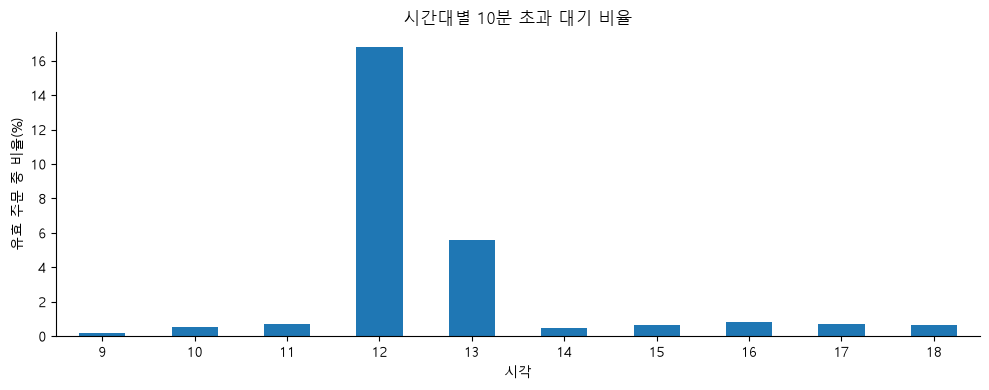

In [ ]:
hour_percent.plot(kind="bar", rot=0)
plt.title("시간대별 10분 초과 대기 비율")
plt.xlabel("시각")
plt.ylabel("유효 주문 중 비율(%)")
plt.tight_layout()
plt.show()

불리언 값의 `sum()`은 `True`의 개수를 셉니다. 이 개수를 유효 주문 수로 나눈 뒤 100을 곱하면 긴 대기 비율(%)이 됩니다. 건수는 긴 대기가 발생한 주문이 얼마나 많은지를, 비율은 해당 시간대의 기록 중 얼마나 자주 발생했는지를 보여 줍니다.

시간대에 따라 비율이 달라지는 것을 확인했으므로, 이번에는 행사 여부에서도 차이가 있는지 봅니다. [교차표와 조건부 비율의 해석](https://openintro-ims.netlify.app/explore-categorical#row-and-column-proportions)

In [ ]:
event_count = valid.groupby("event_day")["long_wait"].count()
event_long = valid.groupby("event_day")["long_wait"].sum()
event_percent = event_long / event_count * 100
event_risk = pd.DataFrame({"count": event_count, "sum": event_long, "percent": event_percent})
event_risk.round(2)

,count,sum,percent
event_day,,,
일반,86519,3524,4.07
행사,15865,1493,9.41


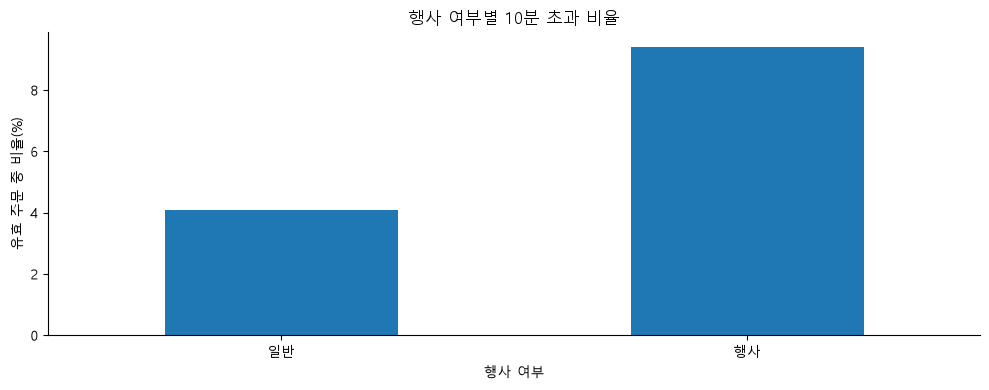

In [ ]:
event_percent.plot(kind="bar", rot=0)
plt.title("행사 여부별 10분 초과 비율")
plt.xlabel("행사 여부")
plt.ylabel("유효 주문 중 비율(%)")
plt.tight_layout()
plt.show()

일반일 약 4.07%, 행사일 약 9.41%로 약 5.34%p 차이가 납니다. 행사일에 긴 대기 비율이 높다는 관계를 관찰했습니다. 다만 두 집단의 시간대 구성도 다를 수 있으므로 전체 비율만으로 설명을 마치지 않습니다.

앞서 직원 수를 비교할 때와 같은 생각을 적용해 12시 안에서 행사 여부를 비교합니다. **조건을 나누는 계산은 같아도, 확인하려는 관계와 분모를 먼저 정해야 합니다.**

In [ ]:
valid12 = valid[valid["order_hour"] == 12]
event12_count = valid12.groupby("event_day")["long_wait"].count()
event12_long = valid12.groupby("event_day")["long_wait"].sum()
event12_percent = event12_long / event12_count * 100

In [ ]:
event_at12 = pd.DataFrame({
    "count": event12_count,
    "sum": event12_long,
    "percent": event12_percent
})
event_at12.round(2)

,count,sum,percent
event_day,,,
일반,18476,2654,14.36
행사,3344,1013,30.29


12시의 긴 대기 비율은 일반일 약 14.36%, 행사일 약 30.29%입니다. 시간대를 같게 놓아도 이 자료에서는 행사일의 비율이 더 높습니다. 직원 수 비교에서는 순서가 바뀌었고, 행사 여부 비교에서는 차이가 유지되었습니다. 조건별 비교의 결과를 미리 정해 두지 않고 계산 결과에 맞추어 설명해야 합니다.

## 전체 경향에서 벗어나는 사례 추적하기

주문이 많을수록 평균 대기가 긴 경향을 보았지만, 산점도에는 주문이 적어도 평균 대기가 긴 점이 있습니다. 이 점들을 살펴보면 전체 평균이나 상관계수에 가려진 상황을 찾을 수 있습니다.

우선 주문 25건 미만이면서 평균 대기가 9분을 넘는 시간대를 골라 봅니다. 이 경계는 사례를 찾기 위한 것이며 오류를 판정하는 기준은 아닙니다.

In [ ]:
few_orders = slot["orders"] < 25
long_wait = slot["wait"] > 9
unusual = slot[few_orders & long_wait]
unusual = unusual.sort_values("wait", ascending=False)
print("조건에 해당하는 시간대:", len(unusual))
unusual.head()

조건에 해당하는 시간대: 11


,order_date,store_location,order_hour,orders,wait,staff,event
401,2026-03-19,도서관점,10,4,18.775000,3.0,일반
2495,2026-06-25,공학관점,14,10,11.766667,3.0,일반
1141,2026-04-23,공학관점,10,11,10.936364,2.0,일반
1415,2026-05-06,공학관점,14,16,10.468750,2.0,일반
374,2026-03-18,도서관점,13,18,9.844444,3.0,일반


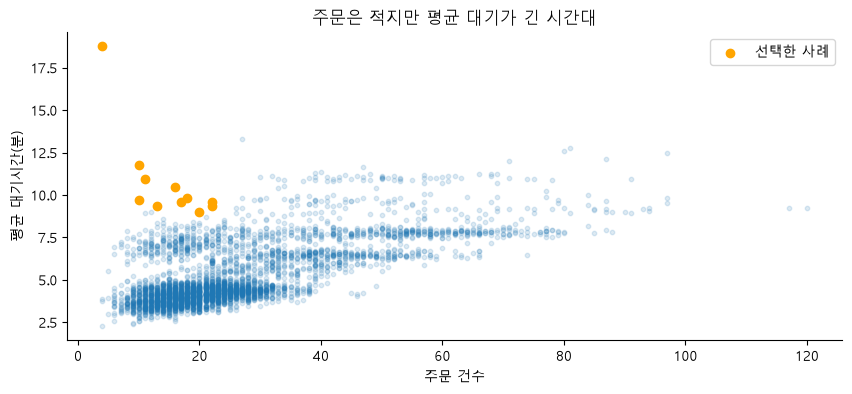

In [ ]:
slot.plot(kind="scatter", x="orders", y="wait", s=10, alpha=0.15)
plt.scatter(unusual["orders"], unusual["wait"], color="orange", label="선택한 사례")
plt.title("주문은 적지만 평균 대기가 긴 시간대")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.legend()
plt.show()

조건에 해당하는 시간대는 11개입니다. 평균 대기가 가장 긴 후보 하나를 선택하고, 집계하기 전 주문 기록으로 돌아갑니다. 날짜·매장·시각 세 조건을 모두 같게 해야 정확히 같은 점의 원자료를 찾을 수 있습니다.

In [ ]:
chosen = unusual.iloc[0]
chosen

order_date        2026-03-19 00:00:00
store_location                   도서관점
order_hour                         10
orders                              4
wait                           18.775
staff                             3.0
event                              일반
Name: 401, dtype: object

첫 후보에서 날짜·매장·시각을 읽어 각각 같은 행을 고릅니다. 조건을 변수로 나누면 어떤 조건으로 선택했는지 확인하기 쉽습니다.

In [ ]:
same_date = data["order_date"] == chosen["order_date"]
same_store = data["store_location"] == chosen["store_location"]
same_hour = data["order_hour"] == chosen["order_hour"]
orders_one_slot = data[same_date & same_store & same_hour]
orders_one_slot[["order_id", "menu_name", "wait_minutes", "staff_count", "event_day"]]

,order_id,menu_name,wait_minutes,staff_count,event_day
10064,12215,아메리카노,2.6,3,일반
10069,12217,카페라테,63.9,3,일반
10074,12216,아메리카노,4.5,3,일반
10084,12218,카페라테,4.1,3,일반


In [ ]:
waits = orders_one_slot["wait_minutes"].dropna()
print("주문 수:", waits.count())
print("평균:", round(waits.mean(), 2))
print("중앙값:", waits.median())
print("최댓값:", waits.max())

주문 수: 4
평균: 18.77
중앙값: 4.3
최댓값: 63.9


선택한 점은 3월 19일 도서관점 10시의 주문 4건입니다. 평균은 약 18.78분이지만 중앙값은 4.30분이고, 63.9분인 주문 한 건이 포함되어 있습니다. 이 시간대의 평균이 높다는 설명에서 **“대부분의 주문이 오래 기다렸다”**는 해석으로 바로 넘어갈 수 없는 이유입니다.

큰 값의 영향을 알아보기 위해 그 값이 없는 경우를 가정하여 평균을 다시 계산합니다. 이것은 결과의 민감도를 살펴보는 계산이며 원자료를 수정하는 작업은 아닙니다.

In [ ]:
largest_order = waits.idxmax()
without_largest = waits.drop(index=largest_order)
print("모든 기록의 평균:", round(waits.mean(), 2))
print("최댓값 한 건을 제외한 평균:", round(without_largest.mean(), 2))
print("모든 기록의 중앙값:", waits.median())
print("최댓값 한 건을 제외한 중앙값:", without_largest.median())

모든 기록의 평균: 18.77
최댓값 한 건을 제외한 평균: 3.73
모든 기록의 중앙값: 4.3
최댓값 한 건을 제외한 중앙값: 4.1


최댓값 한 건을 제외했을 때 평균이 얼마나 바뀌는지 확인합니다. 이 차이는 해당 점이 산점도의 위쪽에 놓인 이유를 설명하는 단서입니다. 63.9분이 실제 지연인지 기록상의 문제인지는 표만으로 판단할 수 없습니다. 주문 접수·제조 시작·완료 시각이나 장비 장애 기록 등을 추가로 확인해야 합니다.

**확인하기:** 예외 후보를 자동으로 삭제하면 어떤 정보를 잃게 될까요? 계산으로 확인한 사실과 추가 확인이 필요한 설명을 나누어 써 봅니다.

## 발견한 관계를 다른 기간에서 재확인하기

탐색 과정에서 주문량–대기시간의 관계와 조건별 차이를 발견했습니다. 이 관계가 한 기간에 집중되어 있는지 살펴보기 위해 3~5월과 6~8월에 같은 분석을 적용합니다. 축 범위를 같게 놓으면 방향과 퍼짐을 직접 비교하기 쉽습니다.

In [ ]:
early = slot[slot["order_date"] < "2026-06-01"]
late = slot[slot["order_date"] >= "2026-06-01"]
early_corr = early["orders"].corr(early["wait"])
late_corr = late["orders"].corr(late["wait"])
print("3~5월:", len(early), "개 시간대 / 상관계수", round(early_corr, 3))
print("6~8월:", len(late), "개 시간대 / 상관계수", round(late_corr, 3))

3~5월: 1950 개 시간대 / 상관계수 0.672
6~8월: 1950 개 시간대 / 상관계수 0.669


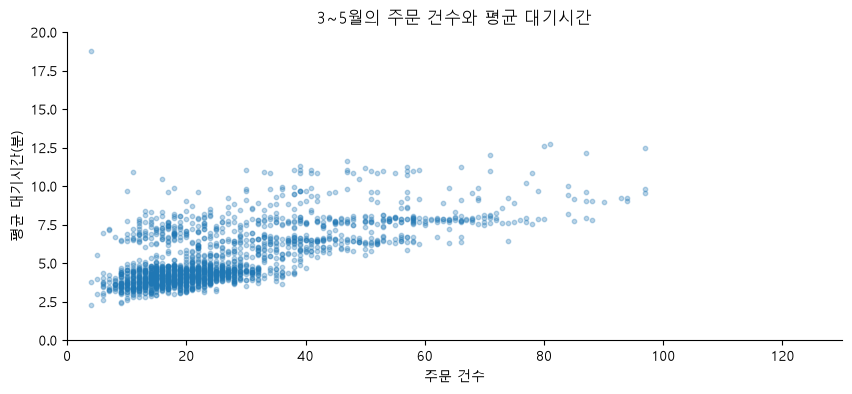

In [ ]:
early.plot(kind="scatter", x="orders", y="wait", s=10, alpha=0.3)
plt.title("3~5월의 주문 건수와 평균 대기시간")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.xlim(0, 130)
plt.ylim(0, 20)
plt.show()

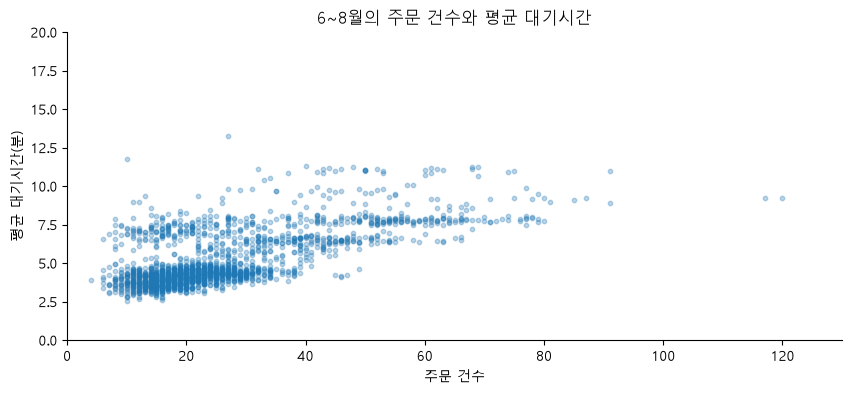

In [ ]:
late.plot(kind="scatter", x="orders", y="wait", s=10, alpha=0.3)
plt.title("6~8월의 주문 건수와 평균 대기시간")
plt.xlabel("주문 건수")
plt.ylabel("평균 대기시간(분)")
plt.xlim(0, 130)
plt.ylim(0, 20)
plt.show()

두 기간은 각각 1,950개 시간대로 이루어지고 상관계수는 모두 약 0.67입니다. 산점도의 우상향과 여러 띠도 비슷하게 관찰됩니다. 주문량과 대기시간의 관계가 한쪽 기간에만 나타난 결과는 아니라는 근거가 됩니다.

같은 방식으로 12시의 직원 수별 차이도 두 기간에서 확인합니다. 평균 대기시간뿐 아니라 각 평균을 계산한 시간대 수를 함께 표시합니다.

In [ ]:
early12 = early[early["order_hour"] == 12]
late12 = late[late["order_hour"] == 12]
early12_wait = early12.groupby("staff")["wait"].mean()
late12_wait = late12.groupby("staff")["wait"].mean()
staff_period_mean = pd.DataFrame({"3~5월": early12_wait, "6~8월": late12_wait})
staff_period_mean.round(2)

,3~5월,6~8월
staff,,
3.0,11.22,11.02
4.0,8.08,7.97


In [ ]:
early12_count = early12.groupby("staff")["wait"].count()
late12_count = late12.groupby("staff")["wait"].count()
period_count = pd.DataFrame({"3~5월": early12_count, "6~8월": late12_count})
period_count

,3~5월,6~8월
staff,,
3.0,30,27
4.0,165,168


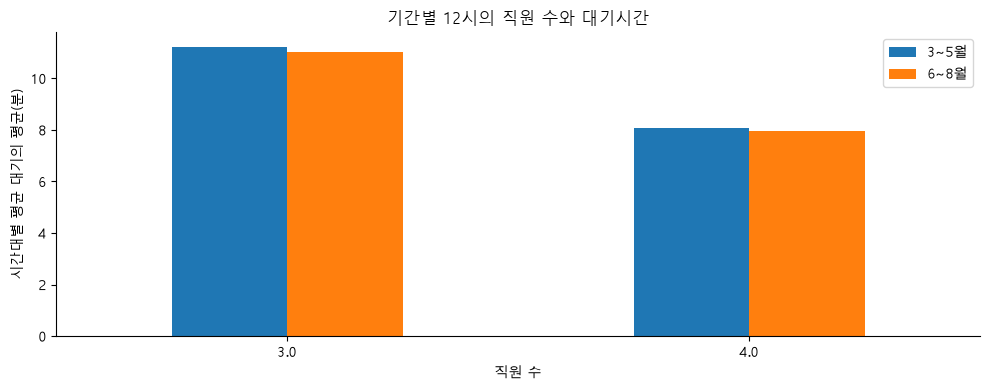

In [ ]:
staff_period_mean.plot(kind="bar", rot=0)
plt.title("기간별 12시의 직원 수와 대기시간")
plt.xlabel("직원 수")
plt.ylabel("시간대별 평균 대기의 평균(분)")
plt.tight_layout()
plt.show()

3~5월에는 직원 3명 약 11.22분, 4명 약 8.08분이고, 6~8월에는 각각 약 11.02분과 7.97분입니다. 두 기간에서 같은 방향의 차이를 관찰했습니다. 기간을 나누어 반복 확인해도 직원 수 이외의 모든 조건이 같아지는 것은 아닙니다.

재확인은 새로운 기간에도 비슷한 관계가 보이는지 확인하는 탐색입니다. 통계적 유의성 검정이나 인과 효과의 추정과 구분해서 해석합니다.

## 관찰한 내용을 결론으로 연결하기

| 처음 발견한 내용 | 추가로 던진 질문 | 계산으로 확인한 내용 |
|---|---|---|
| 날짜별 주문량이 오르내립니다. | 같은 요일에 높은 값이 반복되는가? | 두 기간 모두 금요일의 일평균 주문량이 높습니다. |
| 12~13시에 주문과 대기가 높습니다. | 여러 달에서 같은 주문 최고점이 나타나는가? | 3월과 8월에서 점심의 주문 집중이 반복됩니다. |
| 주문량과 대기시간이 함께 증가합니다. | 비슷한 주문 규모의 띠는 어떤 조건과 연결되는가? | 직원 수별 집단의 위치와 시간대 구성이 다릅니다. |
| 직원 4명 집단의 전체 평균 대기가 높습니다. | 같은 시간대에서도 같은 순서인가? | 12시에서는 직원 4명 집단의 평균 대기가 더 낮습니다. |
| 주문이 적은데 평균 대기가 긴 점이 있습니다. | 해당 점의 원자료는 어떠한가? | 선택한 시간대는 큰 값 한 건이 평균에 영향을 주었습니다. |

다음은 표와 그래프를 근거로 작성할 수 있는 결론의 예입니다.

> 기록된 기간에서는 금요일의 일평균 주문량이 높고, 3월과 8월에서 점심시간의 주문 집중이 반복됩니다. 매장·날짜·시간대별로 주문량과 평균 대기시간 사이에 양의 관계가 관찰되지만, 직원 배치 시간대의 구성도 함께 달라집니다. 전체 직원 수별 평균과 12시의 평균은 순서가 달라 조건을 나누어 해석해야 합니다. 일부 시간대는 큰 대기값 한 건이 평균을 높여 원자료 확인이 필요합니다. 이 결과만으로 주문 증가나 직원 수가 대기시간을 얼마나 변화시키는지는 확정할 수 없습니다.

패턴 탐색은 **관찰한 내용에서 질문을 만들고, 비교 기준을 정해 계산하고, 추가 결과에 맞추어 설명을 고치는 과정**입니다. 예상과 다른 결과가 나오면 그 차이를 설명할 다음 질문을 만듭니다.